# Lecture 4 — Class Exercise
## Scatter & Bubble Charts: Gapminder

> **Push to:** `week04/lecture04_exercise.ipynb`

**Rules:**
1. Colour used **sparingly** — one categorical variable, no rainbow
2. If showing all continents, either use accessible palette OR grey all + highlight one
3. `size_max` set when using bubble size
4. Log scale for GDP per capita
5. Insight title

---


In [2]:
import pandas as pd
import plotly.express as px
import numpy as np
import plotly.graph_objects as go

# Dataset: Gapminder — GDP, Life Expectancy, Population by Country
# Source: Gapminder Foundation (gapminder.org)

df = px.data.gapminder()
print(f"Loaded: {len(df)} rows")
print(df.head())

Loaded: 1704 rows
       country continent  year  lifeExp       pop   gdpPercap iso_alpha  \
0  Afghanistan      Asia  1952   28.801   8425333  779.445314       AFG   
1  Afghanistan      Asia  1957   30.332   9240934  820.853030       AFG   
2  Afghanistan      Asia  1962   31.997  10267083  853.100710       AFG   
3  Afghanistan      Asia  1967   34.020  11537966  836.197138       AFG   
4  Afghanistan      Asia  1972   36.088  13079460  739.981106       AFG   

   iso_num  
0        4  
1        4  
2        4  
3        4  
4        4  


In [3]:
# explore

print(df.info())
print("Years:", sorted(df['year'].unique()))
print("Continents:", df['continent'].unique())
print(df.describe().round(1))


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1704 entries, 0 to 1703
Data columns (total 8 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   country    1704 non-null   object 
 1   continent  1704 non-null   object 
 2   year       1704 non-null   int64  
 3   lifeExp    1704 non-null   float64
 4   pop        1704 non-null   int64  
 5   gdpPercap  1704 non-null   float64
 6   iso_alpha  1704 non-null   object 
 7   iso_num    1704 non-null   int64  
dtypes: float64(2), int64(3), object(3)
memory usage: 106.6+ KB
None
Years: [np.int64(1952), np.int64(1957), np.int64(1962), np.int64(1967), np.int64(1972), np.int64(1977), np.int64(1982), np.int64(1987), np.int64(1992), np.int64(1997), np.int64(2002), np.int64(2007)]
Continents: ['Asia' 'Europe' 'Africa' 'Americas' 'Oceania']
         year  lifeExp           pop  gdpPercap  iso_num
count  1704.0   1704.0  1.704000e+03     1704.0   1704.0
mean   1979.5     59.5  2.960121e+07     7215.3    

## Task 1 — Scatter: life expectancy change over time

**What to build:** A scatter showing **GDP per capita vs life expectancy** for **two years** (2002 and 2007) to show how both moved — use **colour for year** (just 2 colours), **one continent only**.

Choose any continent except Africa (that was the example). Highlight the change direction.

> 💡 Filter: `df.loc[df['continent'] == 'YOUR_CHOICE']` then filter years


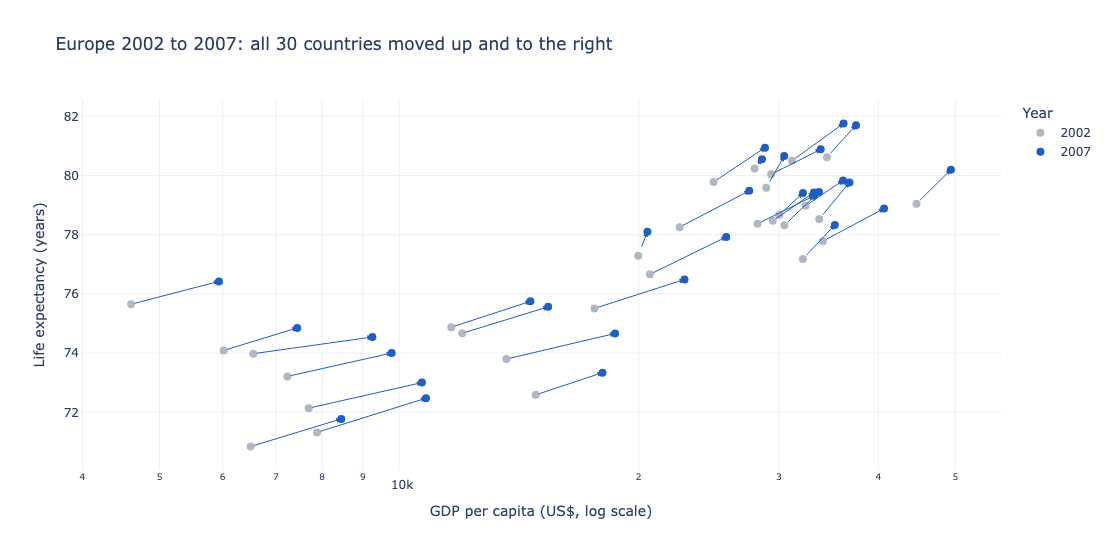

In [4]:
# Task 1 — Solution B: arrows show the direction of change

eu = df.loc[(df['continent'] == 'Europe') & (df['year'].isin([2002, 2007]))]
a = eu[eu['year'] == 2002].set_index('country')
b = eu[eu['year'] == 2007].set_index('country')

fig = go.Figure()
for yr, d, col in [(2002, a, '#B0B7C3'), (2007, b, '#1F5FBF')]:
    fig.add_trace(go.Scatter(
        x=d['gdpPercap'], y=d['lifeExp'], mode='markers', name=str(yr),
        text=d.index, hovertemplate='%{text}<br>GDP: $%{x:,.0f}<br>Life exp: %{y:.1f}<extra>' + str(yr) + '</extra>',
        marker=dict(size=8, color=col)))

# on a log axis, annotation coordinates are in log10 units
for c in a.index:
    fig.add_annotation(
        x=np.log10(b.loc[c, 'gdpPercap']), y=b.loc[c, 'lifeExp'],
        ax=np.log10(a.loc[c, 'gdpPercap']), ay=a.loc[c, 'lifeExp'],
        xref='x', yref='y', axref='x', ayref='y',
        showarrow=True, arrowhead=2, arrowsize=1, arrowwidth=1, arrowcolor='#1F5FBF')

fig.update_xaxes(type='log', title='GDP per capita (US$, log scale)')
fig.update_yaxes(title='Life expectancy (years)')
fig.update_layout(
    title='Europe 2002 to 2007: all 30 countries moved up and to the right',
    template='plotly_white', width=900, height=550, legend_title='Year')
fig.show()


## Task 2 — Bubble chart: tell a story

**What to build:** A bubble chart (full 2007 dataset, all countries) where:
- x = GDP per capita (log scale)
- y = life expectancy
- size = population
- colour = ONE continent highlighted (your choice), all others grey
- At least one annotation explaining the highlighted group's story

> This is the grey-and-highlight technique applied to a bubble chart.


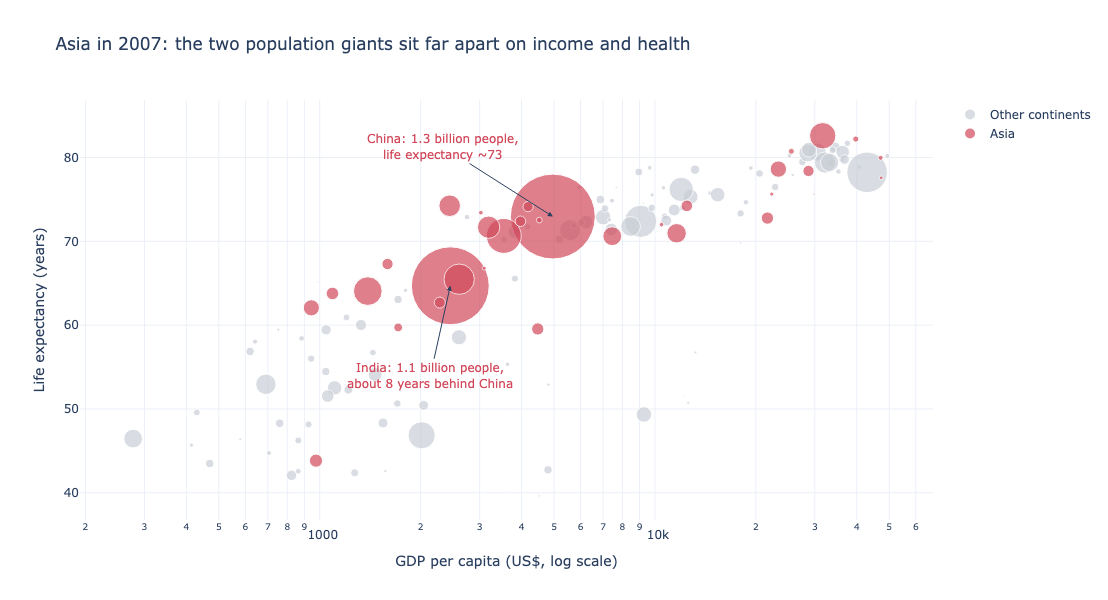

In [5]:
# Task 2
# YOUR CODE HERE
d07 = df.loc[df['year'] == 2007].copy()
d07['group'] = np.where(d07['continent'] == 'Asia', 'Asia', 'Other continents')

fig = px.scatter(
    d07, x='gdpPercap', y='lifeExp', size='pop', color='group',
    log_x=True, size_max=60, hover_name='country',
    category_orders={'group': ['Other continents', 'Asia']},   # Asia drawn last = on top
    color_discrete_map={'Asia': '#D1495B', 'Other continents': '#C9CED6'},
    labels={'gdpPercap': 'GDP per capita (US$, log scale)',
            'lifeExp': 'Life expectancy (years)', 'group': '', 'pop': 'Population'},
    title='Asia in 2007: the two population giants sit far apart on income and health',
)
fig.add_annotation(x=np.log10(4959), y=72.96, text='China: 1.3 billion people,<br>life expectancy ~73',
                   showarrow=True, arrowhead=2, ax=-110, ay=-70, font=dict(color='#D1495B'))
fig.add_annotation(x=np.log10(2452), y=64.7, text='India: 1.1 billion people,<br>about 8 years behind China',
                   showarrow=True, arrowhead=2, ax=-20, ay=90, font=dict(color='#D1495B'))
fig.update_layout(template='plotly_white', width=950, height=600)
fig.show()
